# RMSD distribution of the training data, the effect of the RMSD cutoff and the pose-quality transformation


- **Activity data** (Kinodata-3D, `kinodata_docked_v2.pt`): `predicted_rmsd` is the RMSD *predicted* by the Kinodata-3D docking pipeline for the kept pose. Processing already keeps only the pose with the lowest predicted RMSD per (ligand, kinase, activity type).
- **Pose data** (POSIT cross-docking, `posit_combined.pt`): `predicted_rmsd` holds the *true* RMSD to the crystal pose (same field name).

The first run reads the unfiltered processed datasets (`data/processed/kinodata/kinodata_docked_v2.pt`, `data/processed/davidsdocked/posit_combined.pt`; about 40 GB of memory) and caches the RMSD of every complex in `output/`; later runs read the cache.

Pose-quality classes follow the code: q = 1/(1+exp(0.9·(RMSD−4.5))). "Good" q ≥ 0.8 ↔ RMSD ≤ 2.96 Å; "bad" q ≤ 0.2 ↔ RMSD ≥ 6.04 Å; "medium" in between.



In [1]:
from pathlib import Path

# repo root = first parent folder that contains the kinodata package
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kinodata" / "__init__.py").exists())
OUTPUT = REPO / "analysis_publication" / "output"
OUTPUT.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED = REPO / "data" / "processed"
CUTOFFS = [10, 20]
Q_GOOD, Q_BAD = 0.8, 0.2
RMSD_GOOD = 4.5 - np.log(Q_GOOD / (1 - Q_GOOD)) / 0.9   # 2.96 A
RMSD_BAD = 4.5 + np.log((1 - Q_BAD) / Q_BAD) / 0.9      # 6.04 A
import sys
sys.path.insert(0, str(REPO / "analysis_publication"))
from plot_style import apply_style, COLORS
apply_style()
print(f"good <= {RMSD_GOOD:.2f} A, bad >= {RMSD_BAD:.2f} A")

good <= 2.96 A, bad >= 6.04 A


In [2]:
def per_complex_table(pt_file, cache, keys):
    """predicted_rmsd and metadata of every complex in an unfiltered processed dataset (cached as csv.gz)."""
    if cache.exists():
        return pd.read_csv(cache)
    import torch
    data, _ = torch.load(pt_file)
    store = data._global_store
    cols = {}
    for k in keys:
        if k in store:
            v = store[k]
            cols[k] = v.numpy().ravel() if hasattr(v, "numpy") else list(v)
    df = pd.DataFrame(cols)
    del data
    df.to_csv(cache, index=False)
    return df


activity = per_complex_table(PROCESSED / "kinodata" / "kinodata_docked_v2.pt", OUTPUT / "rmsd_activity.csv.gz",
                             ["predicted_rmsd", "y", "activity_type", "scaffold", "pocket_sequence", "smiles", "ident"])
pose = per_complex_table(PROCESSED / "davidsdocked" / "posit_combined.pt", OUTPUT / "rmsd_pose.csv.gz",
                         ["predicted_rmsd", "scaffold", "pocket_sequence", "smiles", "docking_score", "ident"])
print(f"activity: {len(activity):,} complexes, columns {list(activity.columns)}")
print(f"pose:     {len(pose):,} poses, columns {list(pose.columns)}")

activity: 119,522 complexes, columns ['predicted_rmsd', 'y', 'activity_type', 'scaffold', 'pocket_sequence', 'smiles', 'ident']
pose:     80,155 poses, columns ['predicted_rmsd', 'scaffold', 'pocket_sequence', 'smiles', 'docking_score', 'ident']


## Distributions

The legend gives the number of complexes above each cutoff. Poses without an RMSD are dropped by every cutoff as well and are not included in these counts.

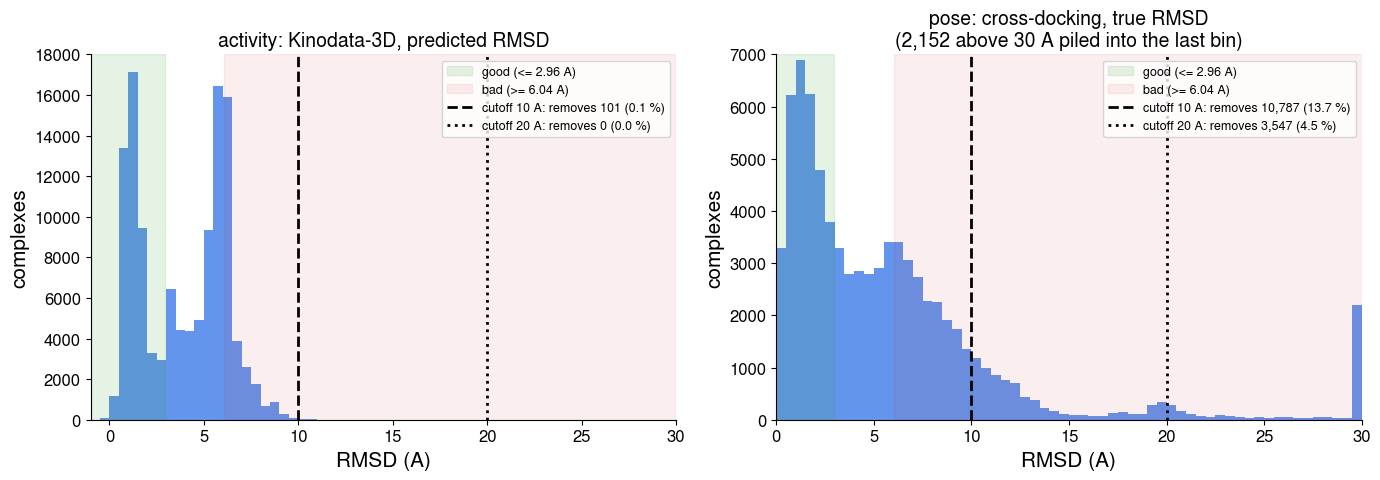

In [3]:
X_MAX = 30  # some poses go up to ~170 A; those above X_MAX are drawn in the last bin (number in the title)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, df) in zip(axes, [("activity: Kinodata-3D, predicted RMSD", activity), ("pose: cross-docking, true RMSD", pose)]):
    r = df["predicted_rmsd"].dropna()
    ax.hist(r.clip(upper=X_MAX), bins=np.arange(np.floor(r.min()), X_MAX + 0.5, 0.5), color=COLORS["hist"])
    ax.axvspan(np.floor(r.min()), RMSD_GOOD, color=COLORS["good"], alpha=0.12, label=f"good (<= {RMSD_GOOD:.2f} A)")
    ax.axvspan(RMSD_BAD, X_MAX, color=COLORS["bad"], alpha=0.08, label=f"bad (>= {RMSD_BAD:.2f} A)")
    for c, ls in zip(CUTOFFS, ["--", ":"]):
        ax.axvline(c, color="k", ls=ls, label=f"cutoff {c} A: removes {int((r > c).sum()):,} ({100 * (r > c).mean():.1f} %)")
    n_out = int((r > X_MAX).sum())
    ax.set(title=name + (f"\n({n_out:,} above {X_MAX} A piled into the last bin)" if n_out else ""),
           xlabel="RMSD (A)", ylabel="complexes", xlim=(np.floor(r.min()), X_MAX))
    ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT / "rmsd_distribution.png")

## Choice of the parameters of the sigmoid transformation

q = 1 / (1 + exp(k · (RMSD − x₀))):
- **x₀** is the midpoint, the RMSD where q = 0.5.
- **k** sets the steepness. q falls from 0.8 to 0.2 over 2·ln(4)/k Å (3.1 Å for k = 0.9: from 2.96 to 6.04 Å).

The question is what the training targets look like for the pose data under different (k, x₀):
- **Too flat (small k):** the targets bunch up in the middle and good and bad poses are hard to tell apart.
- **Too steep (large k):** the target becomes a binary good/bad label with no middle values, so nothing is learned about "medium" poses.
- **Midpoint shifted:** one end of the range is nearly empty (x₀ = 2 Å: hardly any good poses; x₀ = 8 Å: hardly any bad ones).

The reference (0.9, 4.5) spreads the targets over the whole range with both ends populated.

**How to use:** edit `SIGMOID_PARAMS` (and `POSE_CUTOFF`) in the next cell and re-run the cells of this section. Only the pose data is needed (no reload). The first entry is drawn as the reference.

The table reports, per parameter set:
- the q 0.8 → 0.2 window in Å;
- the share of good (q ≥ 0.8), medium and bad (q ≤ 0.2) poses, which with the pose-loss weights 7 / 1 / 10 (good / medium / bad) sets the class balance;
- the share of poses with q in the middle third (1/3–2/3);
- a flatness score: normalized entropy of the q histogram, 1 = perfectly uniform, near 0 = everything in one bin.

This shows the targets only. Whether the *results* are robust to the parameters needs retraining with other values.

In [4]:
# ---- edit me ----------------------------------------------------------------------------------
SIGMOID_PARAMS = [      # (k, x0); the first one is the reference used in the paper
    (0.9, 4.5),
    (0.7, 5.4), (1.25, 4.5), (1.25, 6.0), (1.3, 5.0),   # earlier candidates
    (0.3, 4.5),         # too flat
    (3.0, 4.5),         # too steep: binary, no middle values
    (0.9, 2.0),         # midpoint too low: hardly any pose "good"
    (0.9, 8.0),         # midpoint too high: hardly any pose "bad"
]
POSE_CUTOFF = 10        # RMSD filter on the pose data before transforming (None = all poses with an RMSD)
N_BINS = 40             # bins of the q histograms
# -------------------------------------------------------------------------------------------------

In [5]:
def sigmoid_q(r, k, x0):
    return 1 / (1 + np.exp(k * (np.asarray(r, float) - x0)))


r_pose = pose["predicted_rmsd"].dropna()
if POSE_CUTOFF is not None:
    r_pose = r_pose[r_pose <= POSE_CUTOFF]
print(f"{len(r_pose):,} poses (cutoff: {POSE_CUTOFF} A)")

rows = []
for k, x0 in SIGMOID_PARAMS:
    q = sigmoid_q(r_pose, k, x0)
    p = np.histogram(q, bins=N_BINS, range=(0, 1))[0] / len(q)
    p_nz = p[p > 0]
    rows.append({
        "k": k, "x0": x0,
        "q 0.8->0.2 window (A)": f"{x0 - np.log(4) / k:.2f}-{x0 + np.log(4) / k:.2f}",
        "good % (q>=0.8)": round(100 * np.mean(q >= Q_GOOD), 1),
        "medium %": round(100 * np.mean((q > Q_BAD) & (q < Q_GOOD)), 1),
        "bad % (q<=0.2)": round(100 * np.mean(q <= Q_BAD), 1),
        "middle third % (1/3<q<2/3)": round(100 * np.mean((q > 1 / 3) & (q < 2 / 3)), 1),
        "flatness (norm. entropy)": round(float(-(p_nz * np.log(p_nz)).sum() / np.log(N_BINS)), 2),
    })
sigmoid_table = pd.DataFrame(rows)
sigmoid_table

67,976 poses (cutoff: 10 A)


,k,x0,q 0.8->0.2 window (A),good % (q>=0.8),medium %,bad % (q<=0.2),middle third % (1/3<q<2/3),flatness (norm. entropy)
0,0.90,4.5,2.96-6.04,45.6,27.3,27.1,12.6,0.90
1,0.70,5.4,3.42-7.38,50.1,35.0,14.9,18.0,0.88
2,1.25,4.5,3.39-5.61,49.8,18.7,31.5,9.1,0.78
3,1.25,6.0,4.89-7.11,62.3,20.5,17.1,11.1,0.69
4,1.30,5.0,3.93-6.07,54.4,18.7,26.8,9.0,0.74
5,0.30,4.5,-0.12-9.12,0.0,96.2,3.8,44.0,0.86
6,3.00,4.5,4.04-4.96,55.2,7.7,37.1,3.9,0.47
7,0.90,2.0,0.46-3.54,4.2,46.9,48.8,25.0,0.83
8,0.90,8.0,6.46-9.54,77.1,21.1,1.8,10.3,0.59


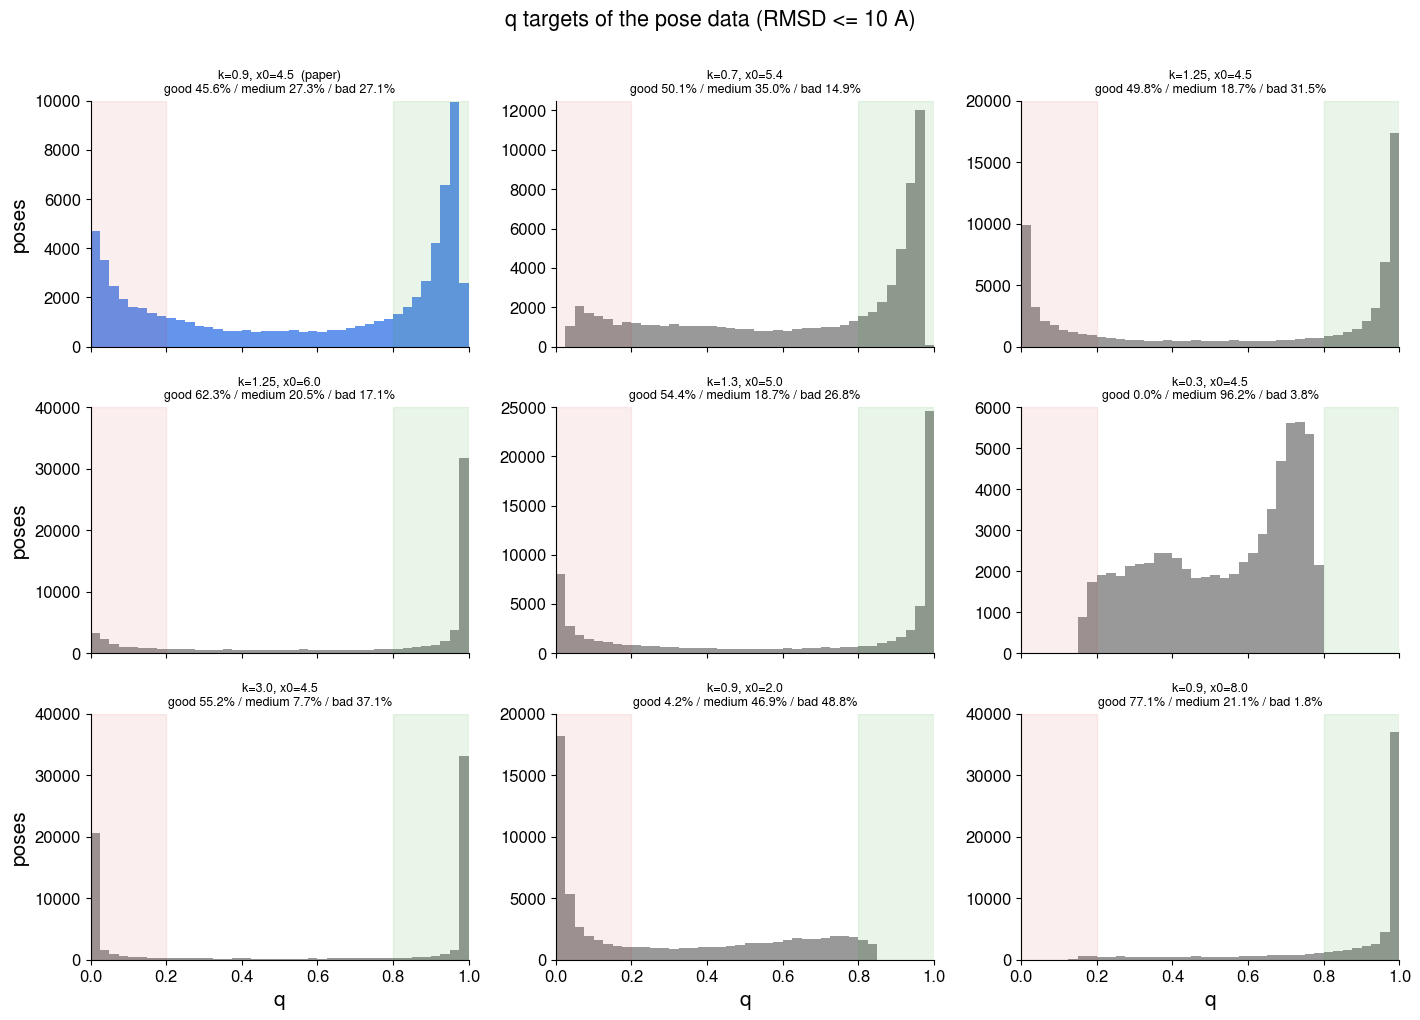

In [6]:
# histogram of the resulting q targets, one panel per parameter set
ncols = 3
nrows = int(np.ceil(len(SIGMOID_PARAMS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.8 * ncols, 3.4 * nrows), sharex=True, squeeze=False)
for ax, (k, x0), row in zip(axes.flat, SIGMOID_PARAMS, rows):
    q = sigmoid_q(r_pose, k, x0)
    ref = (k, x0) == SIGMOID_PARAMS[0]
    ax.hist(q, bins=N_BINS, range=(0, 1), color=COLORS["hist"] if ref else COLORS["neutral"])
    ax.axvspan(0, Q_BAD, color=COLORS["bad"], alpha=0.08)
    ax.axvspan(Q_GOOD, 1, color=COLORS["good"], alpha=0.10)
    ax.set_xlim(0, 1)
    ax.set_title(f"k={k}, x0={x0}" + ("  (paper)" if ref else "") +
                 f"\ngood {row['good % (q>=0.8)']}% / medium {row['medium %']}% / bad {row['bad % (q<=0.2)']}%", fontsize=9)
for ax in axes.flat[len(SIGMOID_PARAMS):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("q")
for ax in axes[:, 0]:
    ax.set_ylabel("poses")
fig.suptitle(f"q targets of the pose data (RMSD <= {POSE_CUTOFF} A)" if POSE_CUTOFF else "q targets of the pose data", y=1.0)
fig.tight_layout()
fig.savefig(OUTPUT / "sigmoid_params_q_hist.png", dpi=600)